# Inside Meta's network: the encoder as a recorded neural population

Earlier notebooks looked at the *inputs* and *outputs* of the problem: the hand pose needs ~8 PCs for 90 % of its
variance (participation ratio PR ≈ 3.2), a linear decoder of the EMG envelopes talks to the pose through a rank-3
"communication subspace" aligned with the top pose PCs (`neural_synergies.ipynb`), and Meta's pretrained regression
model recovers PC1 well and little beyond ~PC4 on this held-out user (`compression_tolerance.ipynb`).

Here we open the box. Meta's model is an **encoder** (a time-depth-separable convolutional network, TDS) that turns
16 channels of raw EMG into **64 features at 25 Hz**, followed by an LSTM **decoder** that turns those features into
joint angles. We treat the 64 encoder features the way a systems neuroscientist treats 64 recorded neurons: the
"neural manifold" view (Gallego et al. 2017; Cunningham & Yu 2014).

| | question | method |
|---|---|---|
| 1 | which pose sample does feature step *j* describe? | receptive field + lagged cross-validated decoding |
| 2 | is the internal representation low-dimensional? | PCA, participation ratio, vs EMG and pose |
| 3 | how many dimensions does a pose readout need? | ridge and reduced-rank regression (RRR), per-pose-PC R² |
| 4 | is the readout aligned with the postural synergies? | principal angles, CCA |
| 5 | how much of the network's activity is "pose-null"? | encoding model (kinematics → feature PCs), the LSTM's own input weights |
| 6 | tracking vs regression checkpoint | everything side by side + CCA between the two networks |

Data: mini dataset (1 user held out from Meta's training, 15 stages, both hands), only the IK-failure-free 11,790-sample
windows that the benchmark's own validation loop uses. `unconstrained` is excluded from all summaries.

## Setup

**Locally:** run `uv sync --extra cpu` in the repo root and pick the **semg2pose** kernel. The cell below does nothing.

**On Colab:** select *Runtime → Change runtime type → Runtime version 2026.07* (Python 3.12), optionally with a T4 GPU.
Run the cell below once; when it says so, do *Runtime → Restart session* and run the notebook from the top again.

In [1]:
# Colab only: clone semg2pose (with the emg2pose submodule) and install it. Locally this does nothing.
import os
import subprocess
import sys
from pathlib import Path

if "google.colab" in sys.modules:
    if not (3, 10) <= sys.version_info[:2] < (3, 13):
        raise RuntimeError("Select Runtime > Change runtime type > Runtime version 2026.07 "
                           "(Python 3.12), then run this cell again.")
    REPO_DIR = Path("/content/semg2pose")
    if not REPO_DIR.exists():
        subprocess.run(["git", "clone", "--recurse-submodules",
                        "https://github.com/eljoserass/semg2pose.git", str(REPO_DIR)], check=True)
    try:
        import semg2pose  # noqa: F401  (installed in a previous run + restart)
        print("semg2pose is installed, continue.")
    except ImportError:
        subprocess.run(["bash", str(REPO_DIR / "scripts" / "colab_setup.sh")], check=True,
                       env={**os.environ, "PYTHON": sys.executable})
        print("Installed. Now: Runtime > Restart session, then run the notebook from the top.")
else:
    print("Local kernel:", sys.executable)

Local kernel: /home/rodri/projects/emg2poseneuromatch/semg2pose/.venv/bin/python


In [2]:
import copy
import json
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display
from scipy import signal
from scipy.ndimage import uniform_filter1d
from scipy.linalg import subspace_angles

from emg2pose.data import WindowedEmgDataset
from semg2pose.data import FS, JOINT_NAMES, download_mini_dataset, list_sessions
from semg2pose.model import download_checkpoints, load_pretrained
from semg2pose.signals import log_envelope

warnings.filterwarnings("ignore")
DATASET_DIR = download_mini_dataset()
CKPT_DIR = download_checkpoints()
torch.set_num_threads(4)
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#9AA1B0"
NETS = ["tracking", "regression", "random net"]
COL = {"tracking": BLUE, "regression": ORANGE, "random net": GREY, "EMG envelopes": GREY, "pose": "k"}
OUT_DIR = os.environ.get("NETWORK_OUT_DIR")   # optional: folder where key figures and numbers are saved
KEY = {}                                      # key numbers, exported at the end

Dataset already downloaded: /home/rodri/emg2pose_dataset_mini
Checkpoints already downloaded: /home/rodri/emg2pose_model_checkpoints


## 0. Where the features sit in time

The encoder uses only *valid* convolutions (no padding) and a total stride of 5 × 2 × 4 × 2 = 80 samples. So on an
11,790-sample window it returns 11,790 − 1,790 = 10,000 / 80 = **125 steps at 25 Hz**. We check exactly which input
samples each output step depends on by back-propagating from one output step to the input (the gradient is non-zero
only inside the receptive field).

In [3]:
modules = {name: load_pretrained(f"{name}_vemg2pose", CKPT_DIR) for name in ["tracking", "regression"]}
net = modules["regression"].model.network
LC = net.left_context
x = torch.randn(1, 16, 11_790, requires_grad=True)
y = net(x)
rows = []
for j in [0, 1, 2, 62, 123, 124]:
    g, = torch.autograd.grad(y[0, :, j].sum(), x, retain_graph=True)
    used = torch.nonzero(g[0].abs().sum(0)).squeeze()
    rows.append({"feature step j": j, "first input sample": used.min().item(), "last input sample": used.max().item(),
                 "last sample − 1790 (= 80 j?)": used.max().item() - LC})
print(f"input (1, 16, 11790) -> output {tuple(y.shape)}; left context = {LC} samples")
display(pd.DataFrame(rows).set_index("feature step j"))
# How Meta's decoder uses the features: linear interpolation (align_corners=True) of 125 steps onto 250 rollout steps
# at 50 Hz, then the 250 predictions are interpolated (align_corners=False) onto the 10,000 samples.
k_of_j = np.arange(125) * 249 / 124
n_of_j = (k_of_j + 0.5) * 40 - 0.5
slope, icpt = np.polyfit(np.arange(125), n_of_j, 1)
print(f"Meta's decoder places feature j at predicted-segment sample ≈ {slope:.1f} j + {icpt:.1f}")
del x, y

Lightning automatically upgraded your loaded checkpoint from v1.8.6 to v2.2.2. To apply the upgrade to your files permanently, run `python -m pytorch_lightning.utilities.upgrade_checkpoint ../../../../emg2pose_model_checkpoints/tracking_vemg2pose.ckpt`


Lightning automatically upgraded your loaded checkpoint from v1.8.6 to v2.2.2. To apply the upgrade to your files permanently, run `python -m pytorch_lightning.utilities.upgrade_checkpoint ../../../../emg2pose_model_checkpoints/regression_vemg2pose.ckpt`


input (1, 16, 11790) -> output (1, 64, 125); left context = 1790 samples


,first input sample,last input sample,last sample − 1790 (= 80 j?)
feature step j,,,
0,0,1790,0
1,80,1870,80
2,160,1950,160
62,4960,6750,4960
123,9840,11630,9840
124,9920,11710,9920


Meta's decoder places feature j at predicted-segment sample ≈ 80.3 j + 19.5


**What we see.** Feature step *j* depends on window samples 80 *j* … 80 *j* + 1,790, i.e. on the last 895 ms of EMG
ending exactly at sample 80 *j* of the predicted 5-s segment. It is strictly causal: the last 79 samples of each window
are never seen. Meta's own decoder (through its two interpolations) uses feature *j* for the pose at sample
≈ 80.3 *j* + 20, i.e. about 10 ms after the last EMG sample the feature has seen. We confirm the alignment empirically
in section 1b.

## 1. Extract the features (both checkpoints) for every valid window

For every recording we build the benchmark's windows (`WindowedEmgDataset(path, 11_790, skip_ik_failures=True)`, as
in `predict_session`), run the full model once with a forward hook on `module.model.network` (so we get the 64
encoder features *and* the end-to-end prediction from the same pass), and keep everything on a common **50 Hz grid of
20-ms bins** relative to the first predicted sample (bin *b* is centred on sample 40 *b*; features fall on the even
bins). Per window we store the joint angles (°), angular velocities (150-ms Savitzky-Golay), the 16 log-envelopes
(20-450 Hz, 50-ms RMS) and the model's predictions on that grid; the features stay at 25 Hz, float32.

As a control we also run a **randomly initialised** copy of the same encoder (same architecture, untrained weights):
whatever structure it shows is inherited from the EMG and the architecture, not learned.

In [4]:
NB0, NB1 = -44, 249                          # 50 Hz bins relative to the first predicted sample
CENTRES = LC + 40 * np.arange(NB0, NB1 + 1)  # their centres inside the 11,790-sample window


def bin50(x):
    """(11790, C) at 2 kHz -> (294, C): mean over [centre - 20, centre + 20) samples."""
    cs = np.vstack([np.zeros((1, x.shape[1])), np.cumsum(x, 0)])
    return ((cs[CENTRES + 20] - cs[CENTRES - 20]) / 40).astype(np.float32)


def deriv(a):
    """Angular velocity (units/s), 150-ms Savitzky-Golay as in neural_synergies.ipynb."""
    return signal.savgol_filter(a, 301, 3, deriv=1, delta=1 / FS, axis=0)


torch.manual_seed(0)
rand_net = copy.deepcopy(net)
for m in rand_net.modules():
    if hasattr(m, "reset_parameters"):
        m.reset_parameters()
rand_net.eval()

sessions = list_sessions(DATASET_DIR)
recs = []
for _, row in sessions.iterrows():
    ds = WindowedEmgDataset(row.path, window_length=11_790, skip_ik_failures=True)
    if len(ds) == 0:
        print(f"no IK-failure-free 11,790-sample window: {row.stage} ({row.side})")
        continue
    batch = torch.utils.data.default_collate([ds[i] for i in range(len(ds))])
    ang = np.degrees(batch["joint_angles"].numpy().astype(np.float64)).transpose(0, 2, 1)   # (N, 11790, 20)
    emg = batch["emg"].numpy().astype(np.float64).transpose(0, 2, 1)                         # (N, 11790, 16)
    rec = {"stage": row.stage, "side": row.side, "n_win": len(ds),
           "ang": np.stack([bin50(a) for a in ang]), "vel": np.stack([bin50(deriv(a)) for a in ang]),
           "env": np.stack([bin50(log_envelope(e, band=(20, 450), window_s=0.05)) for e in emg])}
    pad = lambda p: np.vstack([np.zeros((LC, p.shape[1])), p])   # predictions only exist after the context
    for name, module in modules.items():
        captured = {}
        hook = module.model.network.register_forward_hook(lambda m, i, o: captured.update(f=o.detach()))
        b = dict(batch)
        b["no_ik_failure"] = module.update_ik_failure_mask(b["no_ik_failure"])
        with torch.no_grad():
            pred, _, mask = module.forward(b)
        hook.remove()
        assert mask.all()
        pred = np.degrees(pred.numpy().astype(np.float64)).transpose(0, 2, 1)               # (N, 10000, 20)
        rec[f"feat_{name}"] = captured["f"].numpy().transpose(0, 2, 1).astype(np.float32)    # (N, 125, 64)
        rec[f"pred_{name}"] = np.stack([bin50(pad(p)) for p in pred])
        rec[f"pvel_{name}"] = np.stack([bin50(pad(deriv(p))) for p in pred])
    with torch.no_grad():
        rec["feat_random net"] = rand_net(batch["emg"]).numpy().transpose(0, 2, 1).astype(np.float32)
    recs.append(rec)
    del batch, ang, emg, pred

use = [r for r in recs if r["stage"] != "unconstrained"]
print(f"{sum(r['n_win'] for r in recs)} windows in {len(recs)} recordings; without unconstrained: "
      f"{sum(r['n_win'] for r in use)} windows in {len(use)} recordings = "
      f"{sum(r['n_win'] for r in use) * 125} feature steps = {sum(r['n_win'] for r in use) * 5 / 60:.1f} min")
print("feature array per window:", recs[0]["feat_regression"].shape[1:], recs[0]["feat_regression"].dtype)

no IK-failure-free 11,790-sample window: OneHandedFreeStyle (left)


no IK-failure-free 11,790-sample window: OneHandedFreeStyle (right)


no IK-failure-free 11,790-sample window: FingerFreeform (left)
no IK-failure-free 11,790-sample window: FingerFreeform (right)


130 windows in 26 recordings; without unconstrained: 123 windows in 24 recordings = 15375 feature steps = 10.2 min
feature array per window: (125, 64) float32


## 1b. Alignment check: at which lag do the features best describe the pose?

The receptive field says feature *j* has seen EMG up to sample 80 *j*. Muscles act on the skeleton with an
electromechanical delay (tens of ms), so we expect the features to describe the pose slightly *after* 80 *j*. We scan
the lag between feature step *j* and the angle bin centred on 80 *j* + lag, for lags of ±500 ms in 20-ms steps, and
score each lag by the cross-validated R² of a linear (ridge) readout of the 20 angles and of the 20 angular
velocities from the 64 features. As a sanity check of the bookkeeping, the model's own prediction at 80 *j* should
match the true pose best at lag 0. (To compare all lags on the same samples we use steps *j* ≤ 112, which keeps
every target inside its window.)

**Cross-validation, used everywhere below:** blocked 5-fold *within* each recording (each recording's samples, in time
order, are cut into 5 contiguous blocks; fold *k* = block *k* of every recording), R² pooled over outputs
(variance-weighted).

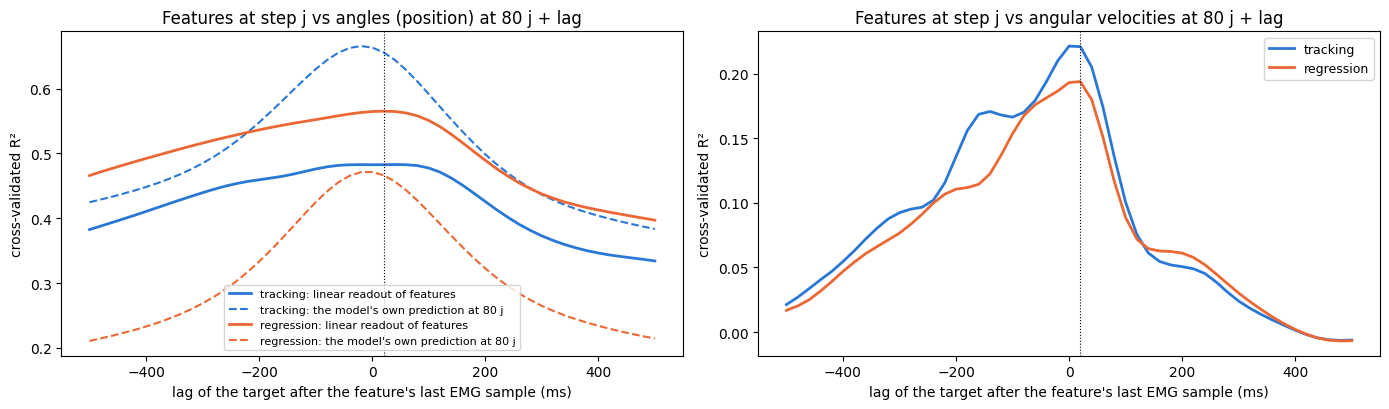

lag of the maximum (ms): {'features → angles [tracking]': 40, 'features → angles [regression]': 20, 'features → velocities [tracking]': 0, 'features → velocities [regression]': 20, 'end-to-end prediction vs angles [tracking]': -20, 'end-to-end prediction vs angles [regression]': 0}
chosen alignment: feature step j <-> angle bin centred on sample 80 j + 40 (+20 ms)
R² at the chosen lag vs at 0 ms:


features → angles          features → velocities          end-to-end prediction vs angles         
net             regression tracking            regression tracking                      regression tracking
lag (ms)                                                                                                   
0                    0.565    0.483                 0.193    0.222                           0.471    0.663
20                   0.565    0.483                 0.194    0.221                           0.466    0.656

In [5]:
def blocked_folds(n, k=5):
    return np.arange(n) * k // n


def ridge_cv(X, Y, folds, lam=1.0):
    """Cross-validated ridge predictions (inputs z-scored on the training folds)."""
    P = np.zeros_like(Y)
    for k in np.unique(folds):
        tr, te = folds != k, folds == k
        mx, sx, my = X[tr].mean(0), X[tr].std(0) + 1e-9, Y[tr].mean(0)
        A, B = (X[tr] - mx) / sx, (X[te] - mx) / sx
        P[te] = B @ np.linalg.solve(A.T @ A + lam * np.eye(A.shape[1]), A.T @ (Y[tr] - my)) + my
    return P


def r2(Y, P):
    return 1 - ((Y - P) ** 2).sum() / ((Y - Y.mean(0)) ** 2).sum()


def r2_cols(Y, P):
    return 1 - ((Y - P) ** 2).sum(0) / ((Y - Y.mean(0)) ** 2).sum(0)


def stack(key, J, recs_=None):
    return np.vstack([r[key][:, J].reshape(-1, r[key].shape[-1]) for r in (recs_ or use)]).astype(np.float64)


J_SCAN = np.arange(113)
LAGS = np.arange(-25, 26)          # in 20-ms bins
folds_scan = np.concatenate([blocked_folds(r["n_win"] * len(J_SCAN)) for r in use])
scan = []
for name in ["tracking", "regression"]:
    X = stack(f"feat_{name}", J_SCAN)
    P_e2e = stack(f"pred_{name}", 2 * J_SCAN - NB0)
    for L in LAGS:
        tb = 2 * J_SCAN + L - NB0
        Ya, Yv = stack("ang", tb), stack("vel", tb)
        scan.append({"net": name, "lag (ms)": 20 * L, "features → angles": r2(Ya, ridge_cv(X, Ya, folds_scan)),
                     "features → velocities": r2(Yv, ridge_cv(X, Yv, folds_scan)),
                     "end-to-end prediction vs angles": r2(Ya, P_e2e)})
scan = pd.DataFrame(scan)
wide = scan.pivot(index="lag (ms)", columns="net")
score = sum(wide[(c, n)] / wide[(c, n)].max() for c in ["features → angles", "features → velocities"]
            for n in ["tracking", "regression"])
LAG = int(score.idxmax() // 20)    # in 20-ms bins

fig, axs = plt.subplots(1, 2, figsize=(14, 4.2))
for name in ["tracking", "regression"]:
    s = scan[scan.net == name].set_index("lag (ms)")
    axs[0].plot(s.index, s["features → angles"], "-", color=COL[name], lw=2, label=f"{name}: linear readout of features")
    axs[0].plot(s.index, s["end-to-end prediction vs angles"], "--", color=COL[name], lw=1.5,
                label=f"{name}: the model's own prediction at 80 j")
    axs[1].plot(s.index, s["features → velocities"], "-", color=COL[name], lw=2, label=name)
for ax, t in zip(axs, ["angles (position)", "angular velocities"]):
    ax.axvline(20 * LAG, color="k", lw=0.8, ls=":")
    ax.set_xlabel("lag of the target after the feature's last EMG sample (ms)")
    ax.set_ylabel("cross-validated R²"); ax.set_title(f"Features at step j vs {t} at 80 j + lag")
axs[0].legend(fontsize=8); axs[1].legend(fontsize=9)
plt.tight_layout(); plt.show()
peaks = {f"{c} [{n}]": int(wide[(c, n)].idxmax()) for c in wide.columns.levels[0] for n in ["tracking", "regression"]}
print("lag of the maximum (ms):", peaks)
print(f"chosen alignment: feature step j <-> angle bin centred on sample 80 j + {40 * LAG} (+{20 * LAG} ms)")
print("R² at the chosen lag vs at 0 ms:")
display(wide.loc[[0, 20 * LAG]].round(3))
KEY["lag_scan"] = {"lag_ms": [int(v) for v in wide.index],
                   **{f"{c} | {n}": wide[(c, n)].round(4).tolist() for c in wide.columns.levels[0]
                      for n in ["tracking", "regression"]}}
KEY["alignment"] = {"chosen_lag_ms": 20 * LAG, "peaks_ms": peaks,
                    "rule": "feature step j (0..124) <-> mean angle over predicted-segment samples "
                            f"[80j+{40 * LAG - 20}, 80j+{40 * LAG + 20}); window sample = 1790 + that"}

**What we see.** The bookkeeping is right: the model's own prediction at sample 80 *j* matches the true pose best at
lag 0 (regression) or −20 ms (tracking). The linear readout of the features peaks a little later: angles at +20 ms
(regression) / +40 ms (tracking), velocities at +20 ms / 0 ms. The position curve is flat over ±60 ms (the pose changes slowly), the velocity curve is sharp and gives
the cleaner estimate. We fix the alignment **feature *j* ↔ pose at sample 80 *j* + 40 (+20 ms)** for everything below,
which is also within 10 ms of where Meta's decoder itself places the features. Choosing 0 ms instead changes the R²
values in the third decimal.

Then we build the pooled dataset: for each step *j*, the 64 features of each network, the 20 angles and velocities at
+20 ms, the model's predictions at the same time, and, as the classical baseline from earlier notebooks, the 16
log-envelopes at 0, 40, 100, 200, 300 ms before the feature's last EMG sample (80 inputs).

In [6]:
J = np.arange(125)
J = J[2 * J + LAG <= NB1]               # the target must lie inside the window
TB = 2 * J + LAG - NB0                  # target bins (array index)
EB = 2 * J - NB0                        # bin of the last EMG sample each feature has seen
ENV_LAGS = [0, 2, 5, 10, 15]            # envelope history in 20-ms bins (0-300 ms)


def aligned(r):
    d = {"Y": r["ang"][:, TB], "V": r["vel"][:, TB],
         "E": np.concatenate([r["env"][:, EB - l] for l in ENV_LAGS], -1)}
    for name in NETS:
        d[f"F_{name}"] = r[f"feat_{name}"][:, J]
    for name in ["tracking", "regression"]:
        d[f"P_{name}"], d[f"PV_{name}"] = r[f"pred_{name}"][:, TB], r[f"pvel_{name}"][:, TB]
    return {k: v.reshape(-1, v.shape[-1]).astype(np.float64) for k, v in d.items()}


parts = [aligned(r) for r in use]
D = {k: np.vstack([p[k] for p in parts]) for k in parts[0]}
folds = np.concatenate([blocked_folds(len(p["Y"])) for p in parts])
rec_id = np.concatenate([np.full(len(p["Y"]), i) for i, p in enumerate(parts)])
side = np.concatenate([np.full(len(p["Y"]), r["side"]) for p, r in zip(parts, use)])
del parts
Y, V = D["Y"], D["V"]
mu_pose = Y.mean(0)
_, s_pose, Vt_pose = np.linalg.svd(Y - mu_pose, full_matrices=False)
ev_pose = s_pose ** 2 / (s_pose ** 2).sum()
Zpose = (Y - mu_pose) @ Vt_pose.T            # 20 pose PC scores
Zvel = V @ Vt_pose.T                          # velocities expressed in the same pose-PC basis
print({k: v.shape for k, v in D.items()})
print(f"{len(Y)} samples at 25 Hz ({len(Y) / 25 / 60:.1f} min) from {len(use)} recordings")

{'Y': (15375, 20), 'V': (15375, 20), 'E': (15375, 80), 'F_tracking': (15375, 64), 'F_regression': (15375, 64), 'F_random net': (15375, 64), 'P_tracking': (15375, 20), 'PV_tracking': (15375, 20), 'P_regression': (15375, 20), 'PV_regression': (15375, 20)}
15375 samples at 25 Hz (10.2 min) from 24 recordings


## 2. Is the internal representation low-dimensional?

**Expectation.** The network's job is to output 20 angles whose variance lives mostly in ~3-8 dimensions, from an EMG
signal whose envelopes are even more compressed (PR ≈ 2.7). A trained encoder could (a) keep a rich, high-dimensional
code (64 features, many "neurons" each tuned to something different), or (b) collapse onto a few dimensions shaped by
the output. Motor cortex recordings typically show (b): a handful of dimensions explain most of the population
variance. We measure the participation ratio PR = (Σλ)² / Σλ² of the covariance spectrum (≈ the number of dimensions
that carry the variance) and the number of PCs for 90 / 95 %, on the same samples for features, envelopes and pose.
Two robustness variants: the correlation matrix (every feature weighted equally) and the "within-recording"
covariance (recording means removed, so differences between hands and tasks do not count as dimensions).

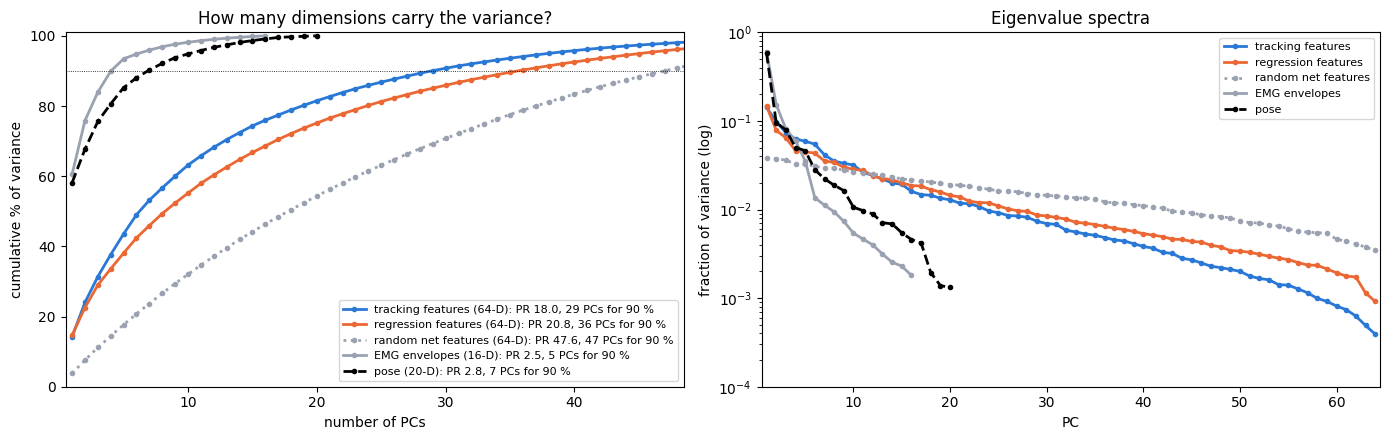

,ambient dim,PR (cov),PR (corr),PR within-recording,PR 200-ms smoothed,PCs for 90 %,PCs for 95 %,% var PC1,% var PC1-3
space,,,,,,,,,
tracking features,64,18.02,24.06,17.15,15.74,29,38,14.19,31.39
regression features,64,20.80,29.36,23.13,16.49,36,46,14.71,28.99
random net features,64,47.57,47.92,47.57,44.76,47,54,3.83,11.19
EMG envelopes,16,2.49,2.50,2.67,2.25,5,7,60.57,83.97
pose,20,2.78,5.54,3.94,2.68,7,11,58.13,75.61


In [7]:
def spectrum(X, corr=False):
    C = np.corrcoef(X.T) if corr else np.cov(X.T)
    ev = np.clip(np.linalg.eigvalsh(C)[::-1], 0, None)
    return ev / ev.sum()


def pr(ev):
    return ev.sum() ** 2 / (ev ** 2).sum()


def n_for(ev, q):
    return int(np.searchsorted(np.cumsum(ev), q) + 1)


def demean_by(X, groups):
    X = X.copy()
    for g in np.unique(groups):
        X[groups == g] -= X[groups == g].mean(0)
    return X


SPACES = {**{f"{n} features": D[f"F_{n}"] for n in NETS}, "EMG envelopes": D["E"][:, :16], "pose": Y}


def pooled_smooth(key, idx, size):
    """Same samples, after a 200-ms moving average inside each window (removes fast fluctuations)."""
    return np.vstack([uniform_filter1d(r[key].astype(np.float64), size, axis=1, mode="nearest")[:, idx]
                      .reshape(-1, r[key].shape[-1]) for r in use])


SMOOTH = {**{f"{n} features": pooled_smooth(f"feat_{n}", J, 5) for n in NETS},
          "EMG envelopes": pooled_smooth("env", EB, 10), "pose": pooled_smooth("ang", TB, 10)}
spec, dim_rows = {}, []
for label, X in SPACES.items():
    ev = spectrum(X)
    spec[label] = ev
    dim_rows.append({"space": label, "ambient dim": X.shape[1], "PR (cov)": pr(ev), "PR (corr)": pr(spectrum(X, True)),
                     "PR within-recording": pr(spectrum(demean_by(X, rec_id))), "PR 200-ms smoothed": pr(spectrum(SMOOTH[label])),
                     "PCs for 90 %": n_for(ev, 0.9), "PCs for 95 %": n_for(ev, 0.95),
                     "% var PC1": 100 * ev[0], "% var PC1-3": 100 * ev[:3].sum()})
dims = pd.DataFrame(dim_rows).set_index("space")

style = {"tracking features": (BLUE, "-"), "regression features": (ORANGE, "-"), "random net features": (GREY, ":"),
         "EMG envelopes": (GREY, "-"), "pose": ("k", "--")}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
for label, ev in spec.items():
    c, ls = style[label]
    k = np.arange(1, len(ev) + 1)
    ax1.plot(k, 100 * np.cumsum(ev), ls, color=c, lw=2, marker="o", ms=3,
             label=f"{label} ({len(ev)}-D): PR {pr(ev):.1f}, {n_for(ev, 0.9)} PCs for 90 %")
    ax2.semilogy(k, ev, ls, color=c, lw=2, marker="o", ms=3, label=label)
ax1.axhline(90, color="k", lw=0.6, ls=":"); ax1.set_xlim(0.5, 48.5); ax1.set_ylim(0, 101)
ax1.set_xlabel("number of PCs"); ax1.set_ylabel("cumulative % of variance"); ax1.legend(fontsize=8, loc="lower right")
ax1.set_title("How many dimensions carry the variance?")
ax2.set_xlim(0.5, 64.5); ax2.set_ylim(1e-4, 1); ax2.set_xlabel("PC"); ax2.set_ylabel("fraction of variance (log)")
ax2.set_title("Eigenvalue spectra"); ax2.legend(fontsize=8)
plt.tight_layout()
if OUT_DIR:
    fig.savefig(os.path.join(OUT_DIR, "figs", "network_dimensionality.png"), dpi=150, bbox_inches="tight")
plt.show()
display(dims.round(2))
del SMOOTH
KEY["dimensionality"] = {label: {"cumvar": np.cumsum(ev).round(4).tolist(), **{k: (round(float(v), 3) if isinstance(v, float) else int(v))
                         for k, v in dims.loc[label].items()}} for label, ev in spec.items()}

**What we see.**

- **The encoder's representation is not low-dimensional.** PR = 18.0 (tracking) and 20.8 (regression) out of 64;
  29 and 36 PCs for 90 % of the variance (38 and 46 for 95 %). PC1 carries only 14 %, the top 3 PCs 29-31 %. The
  eigenvalue spectrum has a long, slowly decaying tail instead of a few dominant components.
- Compare with the same samples: **EMG envelopes PR 2.5** (5 PCs for 90 %) and **pose PR 2.8** (7 PCs for 90 %, 11
  for 95 %; the slightly lower values than the earlier 2.7 and 3.2 come from using only the full windows). So the
  network **expands** the dimensionality of its input by a factor of ~7-8, even though its output is low-dimensional.
- The robustness variants agree: correlation PR 24 / 29, within-recording PR 17 / 23, and after a 200-ms moving
  average still 15.7 / 16.5, so the high dimension is neither differences between tasks and hands nor fast jitter.
- Training does compress: the same architecture with random weights gives PR 47.6 (an almost flat spectrum). But
  that control is weak: its features carry no linearly readable pose or kinematics at all (sections 3 and 5),
  probably because the per-step LayerNorm removes the amplitude shared by all channels and the random filters do not
  smooth the EMG carrier. Read it as "an untrained encoder makes near-isotropic noise", not as a fair baseline.
- In neural-manifold terms the encoder looks more like a high-dimensional **expansion** (a basis of many non-linear
  features, as in a reservoir or the cerebellar granule layer) than like the few-dimensional manifolds of motor
  cortex. The next sections ask where in this 64-D space the pose lives.

## 3. Readout: how many dimensions does a linear pose readout need?

**Expectation.** If the pose information in the features sits in a few directions, a reduced-rank readout should
reach almost the full-rank performance at low rank, like the rank-3 EMG-envelope "communication subspace". We fit
**ridge** (full rank) and **reduced-rank regression** (RRR: ridge fitted values projected on their top-*r* principal
directions in output space, as in `neural_synergies.ipynb`) from the 64 features of the current time step to

- (a) the 20 angles (degrees; R² pooled, so dominated by the high-variance pose directions), and
- (b) the top-8 pose PC scores, each z-scored (every postural synergy counts equally, so the rank tells how many
  *distinct* pose dimensions are decodable).

Baselines on the same samples: the random-weight encoder and the classical envelope decoder (16 log-envelopes × 5
lags). The ridge penalty is picked per input set on the angles from a grid (results are flat around the optimum).

In [8]:
def rrr_cv(X, Y, folds, ranks, lam=1.0):
    """Cross-validated pooled R² of rank-r readouts (ridge fitted values projected on their top-r output directions)."""
    preds = {r: np.zeros_like(Y) for r in ranks}
    full = np.zeros_like(Y)
    for k in np.unique(folds):
        tr, te = folds != k, folds == k
        mx, sx, my = X[tr].mean(0), X[tr].std(0) + 1e-9, Y[tr].mean(0)
        A, B = (X[tr] - mx) / sx, (X[te] - mx) / sx
        W = np.linalg.solve(A.T @ A + lam * np.eye(A.shape[1]), A.T @ (Y[tr] - my))
        full[te] = B @ W + my
        _, _, Vt = np.linalg.svd(A @ W, full_matrices=False)
        for r in ranks:
            preds[r][te] = (B @ W) @ Vt[:r].T @ Vt[:r] + my
    return {r: r2(Y, p) for r, p in preds.items()}, r2(Y, full)


INPUTS = {**{n: D[f"F_{n}"] for n in NETS}, "EMG envelopes": D["E"]}
LAM = {}
for label, X in INPUTS.items():
    scores = {lam: r2(Y, ridge_cv(X, Y, folds, lam)) for lam in [0.1, 1, 10, 100, 1000, 10000]}
    LAM[label] = max(scores, key=scores.get)
print("ridge penalty chosen per input set:", LAM)

Zs = Zpose[:, :8] / Zpose[:, :8].std(0)
RANKS_A, RANKS_B = list(range(1, 13)) + [16, 20], list(range(1, 9))
rrr = {}
for label, X in INPUTS.items():
    rrr[label, "angles"] = rrr_cv(X, Y, folds, RANKS_A, LAM[label])
    rrr[label, "pose PCs (z)"] = rrr_cv(X, Zs, folds, RANKS_B, LAM[label])
rank_rows = []
for (label, target), (curve, full) in rrr.items():
    r90 = next((r for r in curve if curve[r] >= 0.9 * full), None)
    rank_rows.append({"input": label, "target": target, "full-rank R²": full, "rank-1": curve[1], "rank-3": curve[3],
                      "rank for 90 % of full": r90})
ranks_df = pd.DataFrame(rank_rows).set_index(["target", "input"]).sort_index()
display(ranks_df.round(3))

ridge penalty chosen per input set: {'tracking': 100, 'regression': 1000, 'random net': 10000, 'EMG envelopes': 100}


full-rank R²  rank-1  rank-3  rank for 90 % of full
target       input                                                             
angles       EMG envelopes         0.391   0.326   0.362                    3.0
             random net           -0.008  -0.009  -0.008                    NaN
             regression            0.567   0.448   0.514                    3.0
             tracking              0.485   0.395   0.447                    3.0
pose PCs (z) EMG envelopes         0.217   0.049   0.122                    6.0
             random net           -0.010  -0.011  -0.010                    NaN
             regression            0.334   0.071   0.161                    7.0
             tracking              0.260   0.061   0.164                    6.0

**Do the high-variance feature PCs carry the pose?** A different way to ask the same question: keep only the top-*k*
PCs of the features (unsupervised, no pose information used) and decode from them. If the curve saturates at small
*k*, the pose information lives in the dominant dimensions of the network's activity.

In [9]:
KS = [1, 2, 3, 4, 5, 6, 8, 10, 12, 16, 20, 24, 32, 48, 64]
topk, topk_v = {}, {}
for n in NETS:
    F = D[f"F_{n}"] - D[f"F_{n}"].mean(0)
    _, _, Vt_f = np.linalg.svd(F, full_matrices=False)
    S = F @ Vt_f.T
    topk[n] = [r2(Y, ridge_cv(S[:, :k], Y, folds, LAM[n])) for k in KS]
    topk_v[n] = [r2(V, ridge_cv(S[:, :k], V, folds, LAM[n])) for k in KS]
first_k = lambda c: KS[int(np.argmax(np.array(c) >= 0.9 * c[-1]))]
k90 = {n: first_k(topk[n]) for n in NETS}
k90_v = {n: first_k(topk_v[n]) for n in NETS}
print("feature PCs needed for 90 % of the all-64 readout R²: angles", k90, "| velocities", k90_v)
topk_df = pd.concat({"angles": pd.DataFrame(topk, index=KS).T, "velocities": pd.DataFrame(topk_v, index=KS).T})
topk_df.columns.name = "top-k feature PCs"
display(topk_df.round(3))

feature PCs needed for 90 % of the all-64 readout R²: angles {'tracking': 32, 'regression': 20, 'random net': 1} | velocities {'tracking': 24, 'regression': 32, 'random net': 1}


top-k feature PCs         1      2      3      4      5      6      8      10     12     16     20     24     32     48     64
angles     tracking    0.033  0.089  0.111  0.114  0.166  0.168  0.323  0.332  0.355  0.397  0.421  0.435  0.447  0.471  0.484
           regression  0.352  0.388  0.422  0.426  0.429  0.436  0.466  0.477  0.495  0.506  0.523  0.534  0.543  0.558  0.564
           random net -0.017 -0.017 -0.017 -0.017 -0.016 -0.016 -0.016 -0.016 -0.015 -0.015 -0.014 -0.014 -0.012 -0.009 -0.008
velocities tracking    0.104  0.110  0.114  0.117  0.126  0.127  0.155  0.173  0.188  0.194  0.199  0.203  0.208  0.217  0.222
           regression  0.013  0.064  0.075  0.077  0.087  0.109  0.113  0.123  0.129  0.153  0.159  0.169  0.181  0.191  0.196
           random net -0.000 -0.000 -0.000 -0.000 -0.000 -0.000 -0.000 -0.000 -0.000 -0.000 -0.000 -0.000 -0.000 -0.001 -0.001

### Per-pose-PC R²: what the features contain vs what the model delivers

Now per postural synergy: R² of each pose PC score (positions) and of the velocity along each pose PC, for

- the **linear readout of the features** (cross-validated on this user),
- the **end-to-end model** (Meta's LSTM decoder on the same features; no fitting on this user),
- the envelope decoder and the random encoder.

Careful with the comparison: the linear readout is *calibrated on this user* (within-user CV), the end-to-end model
never saw this user. A gap in favour of the linear readout means "the information is in the features, but the
decoder trained on other people does not read it out correctly for this person".

% pose variance per PC: [58.1  9.6  7.9  5.   4.6  2.8  2.2  1.9  1.6  1.1]


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,pooled (20 angles)
"tracking → pose (linear, CV)",0.69,0.36,0.16,0.30,0.05,0.22,0.25,0.05,0.14,0.17,0.48
"tracking → velocity (linear, CV)",0.41,0.22,0.21,0.23,0.14,0.12,0.16,0.02,0.10,0.27,0.22
"regression → pose (linear, CV)",0.78,0.43,0.27,0.33,0.13,0.35,0.31,0.07,0.17,0.22,0.57
"regression → velocity (linear, CV)",0.38,0.20,0.18,0.18,0.07,0.09,0.15,0.03,0.08,0.25,0.20
"random net → pose (linear, CV)",-0.01,-0.01,-0.02,-0.00,-0.02,-0.00,-0.00,-0.02,0.00,-0.00,-0.01
"random net → velocity (linear, CV)",-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00
"EMG envelopes → pose (linear, CV)",0.57,0.21,0.12,0.18,0.04,0.25,0.29,0.07,0.15,0.15,0.39
"EMG envelopes → velocity (linear, CV)",0.31,0.15,0.15,0.17,0.07,0.05,0.16,0.02,0.05,0.21,0.16
tracking end-to-end → pose,0.86,0.61,0.45,0.51,0.32,0.51,0.39,0.16,0.25,0.22,0.66
tracking end-to-end → velocity,0.56,0.29,0.33,0.34,0.18,0.18,0.17,0.05,0.17,0.30,0.31


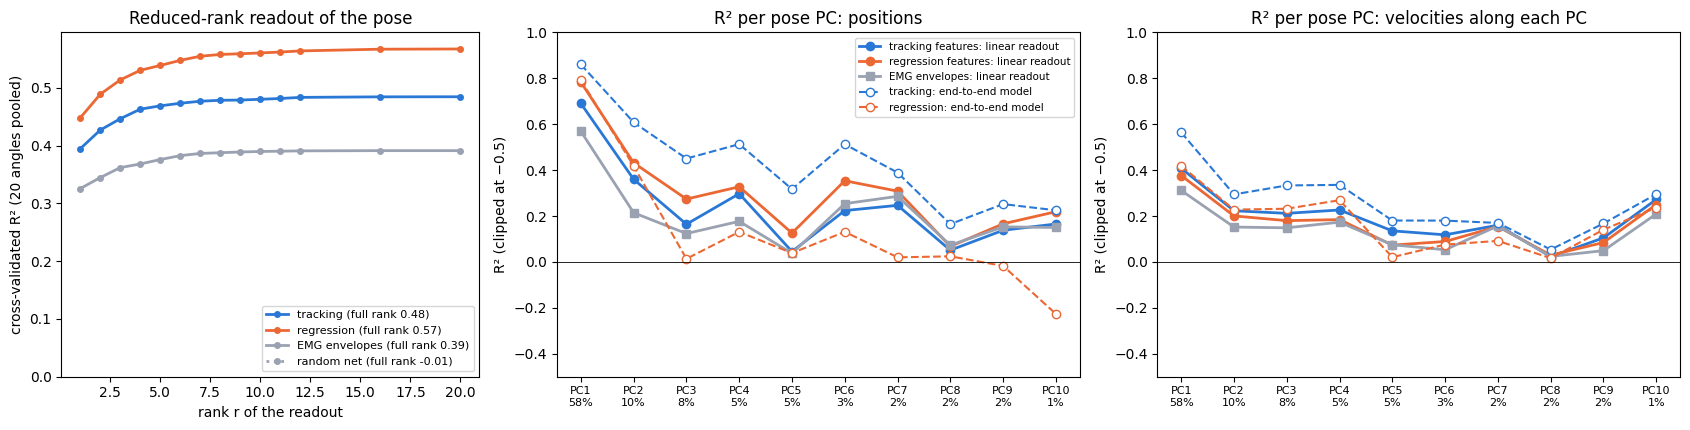

In [10]:
NPC = 10
pc_rows, pooled = {}, {}
for label, X in INPUTS.items():
    Py, Pv = ridge_cv(X, Y, folds, LAM[label]), ridge_cv(X, V, folds, LAM[label])
    pc_rows[f"{label} → pose (linear, CV)"] = r2_cols(Zpose, (Py - mu_pose) @ Vt_pose.T)
    pc_rows[f"{label} → velocity (linear, CV)"] = r2_cols(Zvel, Pv @ Vt_pose.T)
    pooled[f"{label} → pose (linear, CV)"], pooled[f"{label} → velocity (linear, CV)"] = r2(Y, Py), r2(V, Pv)
for n in ["tracking", "regression"]:
    pc_rows[f"{n} end-to-end → pose"] = r2_cols(Zpose, (D[f"P_{n}"] - mu_pose) @ Vt_pose.T)
    pc_rows[f"{n} end-to-end → velocity"] = r2_cols(Zvel, D[f"PV_{n}"] @ Vt_pose.T)
    pooled[f"{n} end-to-end → pose"], pooled[f"{n} end-to-end → velocity"] = r2(Y, D[f"P_{n}"]), r2(V, D[f"PV_{n}"])
perpc = pd.DataFrame(pc_rows, index=[f"PC{i + 1}" for i in range(20)]).T
perpc["pooled (20 angles)"] = pd.Series(pooled)
print("% pose variance per PC:", np.round(100 * ev_pose[:NPC], 1))
display(perpc.iloc[:, list(range(NPC)) + [20]].round(2))

fig, axs = plt.subplots(1, 3, figsize=(17, 4.4), gridspec_kw={"width_ratios": [1, 1.25, 1.25]})
ax = axs[0]
for label, c, ls in [("tracking", BLUE, "-"), ("regression", ORANGE, "-"), ("EMG envelopes", GREY, "-"), ("random net", GREY, ":")]:
    curve, full = rrr[label, "angles"]
    ax.plot(RANKS_A, [curve[r] for r in RANKS_A], ls, color=c, marker="o", ms=4, lw=2,
            label=f"{label} (full rank {full:.2f})")
ax.set_xlabel("rank r of the readout"); ax.set_ylabel("cross-validated R² (20 angles pooled)")
ax.set_title("Reduced-rank readout of the pose"); ax.legend(fontsize=8, loc="lower right"); ax.set_ylim(0, None)
xx = np.arange(NPC)
for ax, kind in zip(axs[1:], ["pose", "velocity"]):
    for label, c, ls, mk in [("tracking", BLUE, "-", "o"), ("regression", ORANGE, "-", "o"),
                             ("EMG envelopes", GREY, "-", "s")]:
        ax.plot(xx, perpc.loc[f"{label} → {kind} (linear, CV)"].values[:NPC], ls, color=c, marker=mk, ms=6, lw=2,
                label=f"{label}{' features' if label != 'EMG envelopes' else ''}: linear readout")
    for n, c in [("tracking", BLUE), ("regression", ORANGE)]:
        ax.plot(xx, perpc.loc[f"{n} end-to-end → {kind}"].values[:NPC], "--", color=c, marker="o", mfc="white",
                ms=6, lw=1.5, label=f"{n}: end-to-end model")
    ax.axhline(0, color="k", lw=0.6)
    ax.set_xticks(xx, [f"PC{i + 1}\n{100 * ev_pose[i]:.0f}%" for i in range(NPC)], fontsize=8)
    ax.set_ylim(-0.5, 1); ax.set_ylabel("R² (clipped at −0.5)")
    ax.set_title(f"R² per pose PC: {'positions' if kind == 'pose' else 'velocities along each PC'}")
axs[1].legend(fontsize=7.5, loc="upper right")
plt.tight_layout()
if OUT_DIR:
    fig.savefig(os.path.join(OUT_DIR, "figs", "network_readout.png"), dpi=150, bbox_inches="tight")
plt.show()
KEY["readout"] = {"ridge_lambda": LAM,
                  "rrr": {f"{lab} | {tgt}": {"ranks": list(c.keys()), "r2": [round(v, 4) for v in c.values()],
                                             "full": round(f, 4)} for (lab, tgt), (c, f) in rrr.items()},
                  "rank_for_90pct": {f"{i[1]} | {i[0]}": (None if pd.isna(v) else int(v))
                                     for i, v in ranks_df["rank for 90 % of full"].items()},
                  "topk_feature_pcs": {"k": KS, **{f"{n} | angles": [round(v, 4) for v in topk[n]] for n in NETS},
                                       **{f"{n} | velocities": [round(v, 4) for v in topk_v[n]] for n in NETS}},
                  "per_pc_r2": {k: [round(float(v), 4) for v in perpc.loc[k].values[:20]] for k in perpc.index},
                  "pooled_r2": perpc["pooled (20 angles)"].round(4).to_dict(),
                  "pose_pc_variance": ev_pose.round(4).tolist()}

**What we see.**

- **The readout itself is low-rank.** Features → 20 angles: full-rank R² = 0.49 (tracking) and 0.57 (regression),
  vs 0.39 for the 80-D envelope decoder and ≈ 0 for the random encoder. **Rank 3 reaches 90 % of full rank for every
  input** (rank 1 already gives 0.40 / 0.45). Equal weight on the 8 pose PCs (z-scored) needs rank 6-7, but the
  full-rank R² there is only 0.26 / 0.33: beyond the first 2-3 directions every extra pose dimension adds little.
- **But the pose does not live in the dominant feature dimensions, especially for tracking.** From the top-3
  feature PCs, tracking reaches R² 0.11 for the angles (of 0.48); 90 % of the full readout needs 32 PCs (regression
  20). Regression's PC1 alone gives 0.35 (of 0.57). For velocities it is the other way round: tracking's PC1 alone
  gives 0.10 (of 0.22), regression's PC1 almost nothing (0.01). Each encoder's dominant dimension reflects its
  training objective (section 5 confirms it): tracking (velocity increments from a known start) leads with
  movement, regression (must output an absolute pose) leads with posture (open/close).
- **Per pose PC** (positions, % pose variance: PC1 58, PC2 10, PC3 8, PC4 5):
  - linear readout of the regression features: 0.78 / 0.43 / 0.27 / 0.33, then 0.1-0.35 up to PC10;
  - the regression end-to-end model on the same samples: 0.79 / 0.42 / **0.01 / 0.13**, ≈ 0 for PC5-9 and −0.23 for
    PC10;
  - tracking features 0.69 / 0.36 / 0.16 / 0.30; the tracking end-to-end model 0.86 / 0.61 / 0.45 / 0.51 (it is given
    the true start pose and integrates);
  - EMG envelopes 0.57 / 0.21 / 0.12 / 0.18: the encoder features beat the classical envelope decoder on every PC.
- **The interesting gap.** For PC1-2 the regression model's decoder gets everything a user-calibrated linear readout
  gets. For PC3-PC10 the features contain linearly decodable information (R² 0.1-0.35 after calibration on this
  user) that the end-to-end model does not deliver on this held-out user. So the "little beyond ~PC4" limit found in
  `compression_tolerance.ipynb` is not an encoder that throws those dimensions away. It looks more like a
  person-specific mapping that the decoder, trained on other people, cannot read out. This points to cheap per-user
  calibration of a low-rank readout as a lever.
- Velocities are hard for everyone: R² ≈ 0.4 on PC1 and ≈ 0.1-0.25 on the rest (tracking end-to-end 0.56 on PC1).

## 4. Is the readout aligned with the postural synergies?

**Principal angles.** From a full-data ridge fit (angles in degrees) we take the top-*r* principal directions of the
fitted values: the *r*-dimensional pose subspace the features predict best (the decodable subspace). We compare it with
the top-*r* pose PCs (mean cos² of the principal angles: 1 = identical, *r*/20 = random). One caveat up front: in
degree units the fitted values inherit the pose variance, so the decodable subspace is pulled toward the top PCs even
if every PC were decoded equally well (in that case the two subspaces would be identical). The per-PC R² above and the
z-scored RRR in section 3 are the variance-free checks.

**CCA.** Canonical correlation between the top-10 feature PCs and the top-8 pose PCs (fitted on 4 folds, correlation
measured on the held-out fold, averaged): how many independent pose combinations are linearly shared with the
network's dominant activity, and which postural synergies they are made of.

cross-validated R² of the null readout: -0.012


r                                                                         1     2     3     4     5     6     7     8
degree units (random = r/20)     tracking                              1.00  0.96  0.79  0.91  0.87  0.86  0.91  0.84
                                 regression                            1.00  0.96  0.91  0.91  0.87  0.92  0.95  0.86
                                 random net                            0.96  0.89  0.80  0.92  0.91  0.87  0.89  0.88
                                 EMG envelopes                         0.99  0.91  0.80  0.78  0.73  0.81  0.91  0.86
                                 null (features of another recording)  0.98  0.70  0.59  0.74  0.77  0.89  0.92  0.84
z-scored pose PCs (random = r/8) tracking                              0.92  0.58  0.62  0.77  0.70  0.82  0.95  1.00
                                 regression                            0.96  0.69  0.62  0.69  0.66  0.83  0.97  1.00
                                 random net                            0.61  0.57  0.53  0.65  0.67  0.76  0.89  1.00
                                 EMG envelopes                         0.83  0.51  0.44  0.56  0.61  0.78  0.92  1.00
                                 null (features of another recording)  0.15  0.34  0.29  0.50  0.61  0.77  0.93  1.00

held-out canonical correlations with the top-8 pose PCs:


CC1   CC2   CC3   CC4   CC5   CC6   CC7   CC8
top-10 input PCs tracking       0.76  0.49  0.28  0.22  0.08  0.11  0.11 -0.02
                 regression     0.86  0.65  0.44  0.50  0.30  0.05  0.09  0.08
                 random net     0.05  0.03  0.05  0.01  0.00  0.01 -0.01  0.00
                 EMG envelopes  0.73  0.66  0.46  0.33  0.20  0.12  0.05 -0.04
top-30 input PCs tracking       0.83  0.71  0.47  0.39  0.38  0.23  0.18  0.12
                 regression     0.88  0.76  0.47  0.63  0.52  0.42  0.26  0.19
                 random net     0.12  0.05  0.05  0.01  0.02  0.01  0.01  0.01
                 EMG envelopes  0.78  0.67  0.49  0.45  0.42  0.23  0.18  0.14

tracking: |corr| of the first 3 pose canonical variates with pose PC1-8
      PC1   PC2   PC3   PC4   PC5   PC6   PC7   PC8
CV1  0.93  0.17  0.15  0.26  0.02  0.14  0.04  0.02
CV2  0.26  0.48  0.06  0.54  0.01  0.32  0.54  0.09
CV3  0.18  0.66  0.47  0.13  0.00  0.02  0.47  0.28
regression: |corr| of the first 3 pose canonical variates with pose PC1-8
      PC1   PC2   PC3   PC4   PC5   PC6   PC7   PC8
CV1  0.97  0.15  0.09  0.07  0.04  0.11  0.01  0.03
CV2  0.17  0.55  0.10  0.57  0.02  0.33  0.46  0.03
CV3  0.00  0.62  0.65  0.31  0.21  0.22  0.05  0.00


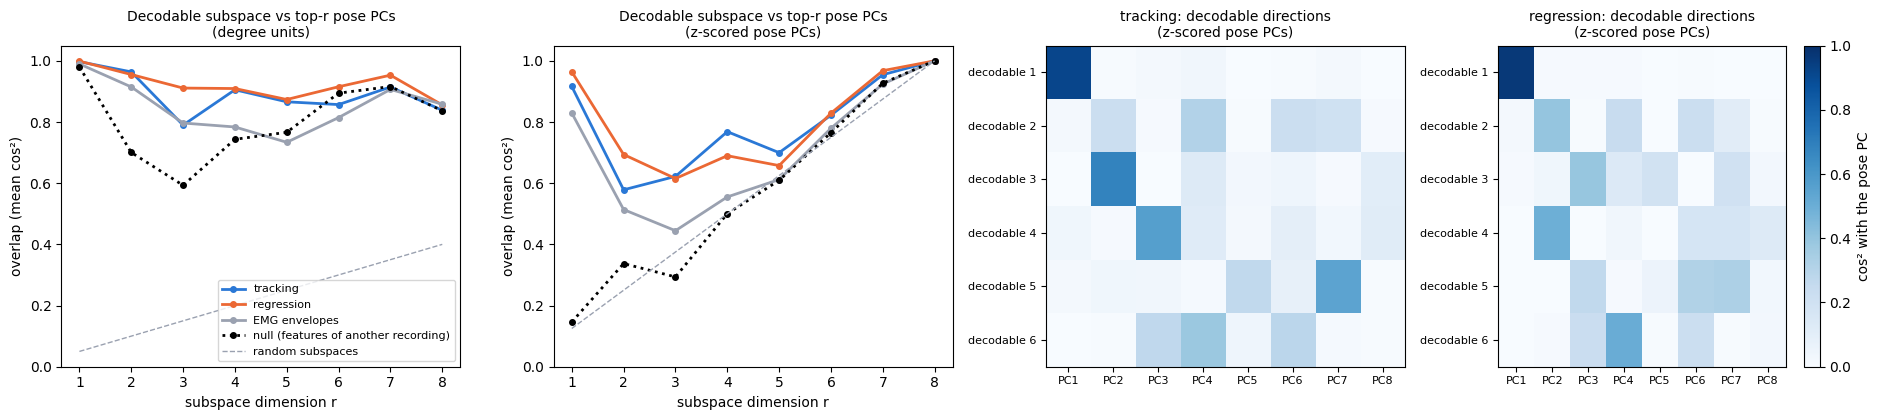

In [11]:
def decodable_subspace(X, Y, lam):
    A = (X - X.mean(0)) / (X.std(0) + 1e-9)
    W = np.linalg.solve(A.T @ A + lam * np.eye(A.shape[1]), A.T @ (Y - Y.mean(0)))
    _, _, Vt = np.linalg.svd(A @ W, full_matrices=False)
    return Vt, W


NULL = "null (features of another recording)"
perm = np.roll(np.arange(len(Y)), len(Y) // 2)   # pairs every sample with the features of a different recording
ALIGN = {**INPUTS, NULL: D["F_regression"][perm]}
LAM[NULL] = LAM["regression"]
print(f"cross-validated R² of the null readout: {r2(Y, ridge_cv(ALIGN[NULL], Y, folds, LAM[NULL])):.3f}")
R_MAX = 8
overlap, overlap_w, comp_w = {}, {}, {}
for label, X in ALIGN.items():
    Vt_dec, _ = decodable_subspace(X, Y, LAM[label])            # in degree units
    overlap[label] = [np.mean(np.cos(subspace_angles(Vt_dec[:r].T, Vt_pose[:r].T)) ** 2) for r in range(1, R_MAX + 1)]
    Vt_w, _ = decodable_subspace(X, Zs, LAM[label])              # in z-scored pose-PC units (8 synergies)
    overlap_w[label] = [np.sum(Vt_w[:r, :r] ** 2) / r for r in range(1, R_MAX + 1)]
    comp_w[label] = Vt_w[:6] ** 2
ov_df = pd.concat({"degree units (random = r/20)": pd.DataFrame(overlap, index=range(1, R_MAX + 1)).T,
                   "z-scored pose PCs (random = r/8)": pd.DataFrame(overlap_w, index=range(1, R_MAX + 1)).T})
ov_df.columns.name = "r"
display(ov_df.round(2))


def inv_sqrt(C):
    w, U = np.linalg.eigh(C)
    return U @ np.diag(1 / np.sqrt(np.clip(w, 1e-12, None))) @ U.T


def cca_fit(A, B):
    A, B = A - A.mean(0), B - B.mean(0)
    n = len(A)
    Wa, Wb = inv_sqrt(A.T @ A / n), inv_sqrt(B.T @ B / n)
    U, s, Vt = np.linalg.svd(Wa @ (A.T @ B / n) @ Wb)
    return Wa @ U, Wb @ Vt.T, s


def cca_cv(A, B, folds):
    """Held-out canonical correlations, averaged over the 5 folds."""
    m = min(A.shape[1], B.shape[1])
    cc = []
    for k in np.unique(folds):
        tr, te = folds != k, folds == k
        Pa, Pb, _ = cca_fit(A[tr], B[tr])
        ua, ub = (A[te] - A[tr].mean(0)) @ Pa[:, :m], (B[te] - B[tr].mean(0)) @ Pb[:, :m]
        cc.append([np.corrcoef(ua[:, i], ub[:, i])[0, 1] for i in range(m)])
    return np.mean(cc, 0)


def top_pcs(X, k):
    Xc = X - X.mean(0)
    _, _, Vt = np.linalg.svd(Xc, full_matrices=False)
    return Xc @ Vt[:k].T


cca_res, cca_res30, cca_load = {}, {}, {}
for label in INPUTS:
    Fk = top_pcs(INPUTS[label], 10)
    cca_res[label] = cca_cv(Fk, Zpose[:, :8], folds)
    cca_res30[label] = cca_cv(top_pcs(INPUTS[label], 30), Zpose[:, :8], folds)
    Pa, Pb, s_in = cca_fit(Fk, Zpose[:, :8])
    ub = (Zpose[:, :8] - Zpose[:, :8].mean(0)) @ Pb
    cca_load[label] = np.array([[abs(np.corrcoef(ub[:, i], Zpose[:, j])[0, 1]) for j in range(8)] for i in range(3)])
cca_df = pd.concat({"top-10 input PCs": pd.DataFrame(cca_res, index=[f"CC{i + 1}" for i in range(8)]).T,
                    "top-30 input PCs": pd.DataFrame(cca_res30, index=[f"CC{i + 1}" for i in range(8)]).T})
print("held-out canonical correlations with the top-8 pose PCs:")
display(cca_df.round(2))
for label in ["tracking", "regression"]:
    print(f"{label}: |corr| of the first 3 pose canonical variates with pose PC1-8")
    print(pd.DataFrame(cca_load[label], index=["CV1", "CV2", "CV3"], columns=[f"PC{j + 1}" for j in range(8)]).round(2).to_string())

fig, axs = plt.subplots(1, 4, figsize=(19, 4.3), gridspec_kw={"width_ratios": [1, 1, 0.9, 0.9]})
rr = np.arange(1, R_MAX + 1)
for ax, ov, base, unit in [(axs[0], overlap, rr / 20, "degree units"), (axs[1], overlap_w, rr / 8, "z-scored pose PCs")]:
    for label, c, ls in [("tracking", BLUE, "-"), ("regression", ORANGE, "-"), ("EMG envelopes", GREY, "-"),
                         (NULL, "k", ":")]:
        ax.plot(rr, ov[label], ls, color=c, marker="o", ms=4, lw=2, label=label)
    ax.plot(rr, base, "--", color=GREY, lw=1, label="random subspaces")
    ax.set_ylim(0, 1.05); ax.set_xlabel("subspace dimension r"); ax.set_ylabel("overlap (mean cos²)")
    ax.set_title(f"Decodable subspace vs top-r pose PCs\n({unit})", fontsize=10)
axs[0].legend(fontsize=8, loc="lower right")
for ax, label in zip(axs[2:], ["tracking", "regression"]):
    im = ax.imshow(comp_w[label], cmap="Blues", vmin=0, vmax=1, aspect="auto")
    ax.set_xticks(range(8), [f"PC{i + 1}" for i in range(8)], fontsize=8)
    ax.set_yticks(range(6), [f"decodable {i + 1}" for i in range(6)], fontsize=8)
    ax.set_title(f"{label}: decodable directions\n(z-scored pose PCs)", fontsize=10)
plt.colorbar(im, ax=axs[3], label="cos² with the pose PC")
plt.tight_layout()
if OUT_DIR:
    fig.savefig(os.path.join(OUT_DIR, "figs", "network_alignment.png"), dpi=150, bbox_inches="tight")
plt.show()
KEY["alignment_subspace"] = {"overlap_degree_units": {k: [round(v, 4) for v in vals] for k, vals in overlap.items()},
                             "overlap_zscored_pose_pcs": {k: [round(float(v), 4) for v in vals] for k, vals in overlap_w.items()},
                             "random_degree_units": (rr / 20).tolist(), "random_zscored": (rr / 8).tolist(),
                             "cca_heldout_top10_vs_pose8": {k: [round(float(v), 4) for v in vals] for k, vals in cca_res.items()},
                             "cca_heldout_top30_vs_pose8": {k: [round(float(v), 4) for v in vals] for k, vals in cca_res30.items()}}

**What we see.**

- **The degree-unit overlap is uninformative on its own.** Tracking / regression / envelopes reach 0.79-0.91 at
  r = 3, but so does the random encoder (0.80, with zero decoding R²), and the null that pairs every sample with the
  features of *another* recording (CV R² −0.01) still gives 0.98 at r = 1 and 0.59 at r = 3 (random subspaces: 0.15).
  The fitted values inherit the pose covariance whatever the input. This also weakens the H3 result of
  `neural_synergies.ipynb` (envelope decoder "aligned with the top pose PCs"), which used the same metric without a
  null.
- **In z-scored pose-PC units the null drops to chance** (0.15 / 0.34 / 0.29 at r = 1 / 2 / 3, random 0.125 /
  0.25 / 0.375). The trained features stay well above it: **0.92 (tracking) and 0.96 (regression) at r = 1** (the most
  decodable synergy *is* PC1), then 0.58-0.69 at r = 2 and 0.62 at r = 3. The envelopes give 0.83 / 0.51 / 0.44. (The
  random encoder gives 0.61 at r = 1 despite R² ≈ 0: a heavily regularised fit on pure noise still leans to the
  slowest PC, one more reason to trust the cross-validated measures.)
- The heatmaps show what the next decodable directions are: tracking's are close to single PCs (PC2, PC3, PC7);
  regression's 2nd-6th directions are **mixtures** of PC2, PC4, PC6, PC7. Beyond PC1, the decodable subspace is not
  a clean subset of the postural synergies.
- **CCA** (held out) says the same with a variance-free method. Top-10 feature PCs vs top-8 pose PCs: tracking 0.76 /
  0.49 / 0.28 / 0.22, regression 0.86 / 0.65 / 0.44 / 0.50 / 0.30, envelopes 0.73 / 0.66 / 0.46 / 0.33. With the
  top-30 feature PCs: tracking 0.83 / 0.71 / 0.47, regression 0.88 / 0.76 / 0.47 / 0.63 / 0.52 / 0.42. The first pose
  canonical variate is PC1 (|r| = 0.93 / 0.97). The second mixes PC2, PC4, PC6, PC7, the third PC2 and PC3. Tracking
  needs many more feature PCs than regression to reach the same correlations, as in section 3.
- **Answer to the alignment question:** yes for the first dimension (open/close, PC1), partly for the next 1-2,
  and beyond that the network's pose-related directions cut across the synergies.

## 5. How much of the network's activity is about the pose? (pose-potent vs pose-null)

In motor cortex, much population activity is **output-null**: it varies, but in directions the downstream readout
ignores (Kaufman et al. 2014). Two ways to ask the same question of the encoder, with very different biases:

- **Decoding view (biased):** the fraction of feature variance in the 3 input-side directions of the rank-3 readout.
  Regression weights divide by the input covariance, so these directions are pushed toward *low-variance* directions
  and this fraction is biased low.
- **Encoding view (preferred):** predict each feature PC from the kinematics (20 angles + positive and negative parts
  of the 20 velocities, at the aligned time) and sum the explained variance. This asks "how much of each dimension of
  network activity is explained by what the hand is doing?" without dividing by the feature covariance. The same
  model on the 16 log-envelopes gives the reference for the EMG itself.

In [12]:
K_kin = np.hstack([Y, np.clip(V, 0, None), np.clip(-V, 0, None)])
K_parts = {"angles only": Y, "velocities only": np.hstack([np.clip(V, 0, None), np.clip(-V, 0, None)])}
enc, enc_tot, enc_split, dec_view, enc_pr = {}, {}, {}, {}, {}
spaces_enc = {**{n: D[f"F_{n}"] for n in NETS}, "EMG envelopes": D["E"][:, :16]}
for label, F in spaces_enc.items():
    Fc = F - F.mean(0)
    ev, U = np.linalg.eigh(np.cov(Fc.T)); ev, U = ev[::-1], U[:, ::-1]
    S = Fc @ U
    P = ridge_cv(K_kin, S, folds, 10.0)
    enc[label] = r2_cols(S, P)
    enc_tot[label] = r2(S, P)          # = variance-weighted mean of the per-PC R²
    enc_pr[label] = {"PR of the kinematics-explained part": pr(np.clip(np.linalg.eigvalsh(np.cov(P.T)), 0, None)),
                     "PR of the unexplained part": pr(np.clip(np.linalg.eigvalsh(np.cov((S - P).T)), 0, None))}
    for part, Kp in K_parts.items():
        Pp = ridge_cv(Kp, S, folds, 10.0)
        enc_split[label, part] = r2_cols(S, Pp)[:6].tolist() + [r2(S, Pp)]
    # decoding view, in z-scored feature units
    Fz = Fc / Fc.std(0)
    W = np.linalg.solve(Fz.T @ Fz + 1.0 * np.eye(Fz.shape[1]), Fz.T @ (Y - mu_pose))
    _, _, Vr = np.linalg.svd(Fz @ W, full_matrices=False)
    U_pot = np.linalg.svd(W @ Vr[:3].T, full_matrices=False)[0]
    Cz = np.cov(Fz.T); evz = np.linalg.eigvalsh(Cz)[::-1]
    dec_view[label] = {"in 3 readout-potent dirs": np.trace(U_pot.T @ Cz @ U_pot) / np.trace(Cz),
                       "in top-3 PCs": evz[:3].sum() / evz.sum(), "random 3-D": 3 / F.shape[1]}
enc_df = pd.DataFrame({k: v[:12] for k, v in enc.items() if k != "EMG envelopes"}, index=[f"PC{i + 1}" for i in range(12)]).T
print("R² of each feature PC from the kinematics (encoding view):")
display(enc_df.round(2))
print("which kinematics? R² of feature PC1-6 and of all feature variance, from angles only vs velocities only:")
display(pd.DataFrame(enc_split, index=[f"PC{i + 1}" for i in range(6)] + ["all variance"]).T.round(2))
summary5 = pd.DataFrame({label: {"variance explained by kinematics (encoding)": enc_tot[label], **dec_view[label]}
                         for label in spaces_enc}).T
display((100 * summary5).round(1).rename(columns=lambda c: f"% {c}"))
display(pd.DataFrame(enc_pr).T.round(1))

R² of each feature PC from the kinematics (encoding view):


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12
tracking,0.55,0.41,0.30,0.21,0.32,0.08,0.38,0.24,0.13,0.26,0.13,0.18
regression,0.72,0.54,0.42,0.17,0.31,0.29,0.30,0.24,0.22,0.17,0.23,0.18
random net,-0.00,-0.00,-0.01,-0.01,-0.00,-0.01,-0.00,-0.00,-0.01,-0.00,0.00,-0.00


which kinematics? R² of feature PC1-6 and of all feature variance, from angles only vs velocities only:


PC1   PC2   PC3   PC4   PC5   PC6  all variance
tracking      angles only      0.14  0.18  0.05  0.04  0.15  0.05          0.09
              velocities only  0.42  0.25  0.26  0.18  0.21  0.04          0.16
regression    angles only      0.65  0.24  0.32  0.06  0.03  0.19          0.19
              velocities only  0.20  0.34  0.16  0.11  0.26  0.11          0.11
random net    angles only      0.00 -0.00 -0.00 -0.00  0.00 -0.00         -0.00
              velocities only -0.00 -0.00 -0.00 -0.01 -0.00 -0.00         -0.00
EMG envelopes angles only      0.12  0.17  0.13  0.11  0.18  0.04          0.12
              velocities only  0.14  0.11  0.05  0.06  0.03  0.01          0.11

,% variance explained by kinematics (encoding),% in 3 readout-potent dirs,% in top-3 PCs,% random 3-D
tracking,24.3,4.0,24.2,4.7
regression,27.4,7.5,21.2,4.7
random net,-0.5,3.3,11.0,4.7
EMG envelopes,22.9,5.8,83.2,18.8


,PR of the kinematics-explained part,PR of the unexplained part
tracking,6.8,23.2
regression,6.1,32.6
random net,22.7,47.6
EMG envelopes,2.1,2.6


**How does Meta's own decoder read the features?** The LSTM's first layer sees the 64 features through its input
weights W (2048 × 64; the other 20 inputs are the previous pose). The input drive a feature PC *k* delivers is
λ_k ‖W u_k‖², where λ_k is that PC's variance and u_k its direction. If the decoder mostly listens to the dominant
dimensions of the encoder, the drive is concentrated on the top PCs; if it relies on small-variance dimensions, it is
spread out. (This is a first-order view: the LSTM gates are non-linear.)

,% drive top-3 PCs,% variance top-3 PCs,% drive top-10 PCs,% variance top-10 PCs,PCs for 90 % of drive,PCs for 90 % of variance,PR of drive
tracking,44.3,31.4,78.4,63.2,18.0,29.0,11.1
regression,36.5,29.0,65.2,55.2,28.0,36.0,14.8


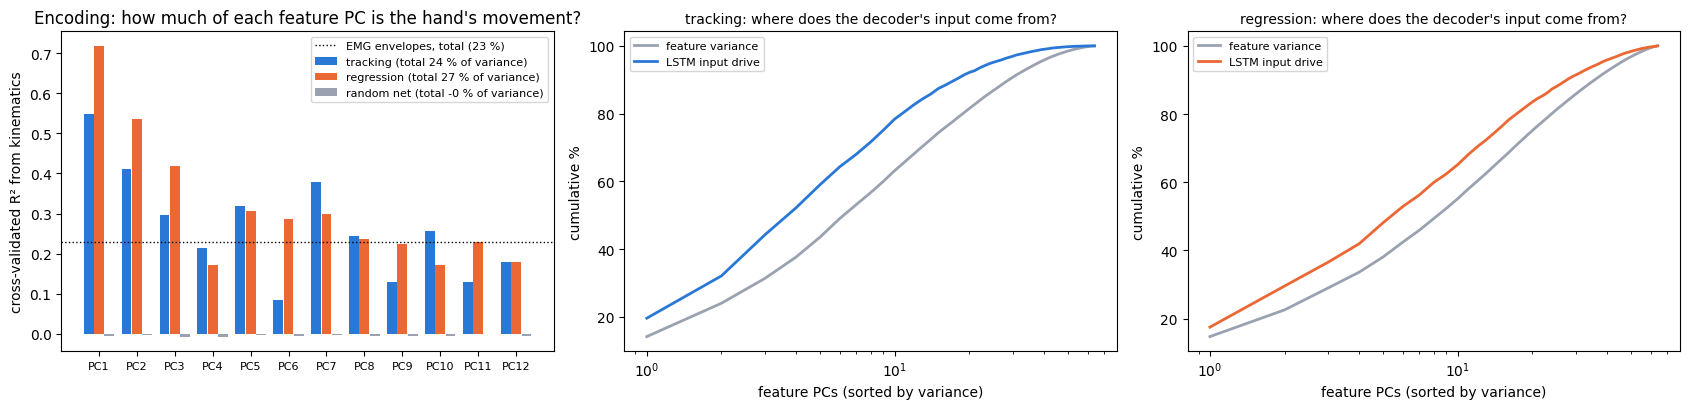

In [13]:
drive = {}
for n in ["tracking", "regression"]:
    Wf = modules[n].model.decoder.lstm.weight_ih_l0[:, :64].detach().numpy().astype(np.float64)
    F = D[f"F_{n}"]
    ev, U = np.linalg.eigh(np.cov(F.T)); ev, U = ev[::-1], U[:, ::-1]
    d = ev * (np.linalg.norm(Wf @ U, axis=0) ** 2)
    drive[n] = {"drive": d / d.sum(), "var": ev / ev.sum()}
drive_rows = {n: {"% drive top-3 PCs": 100 * v["drive"][:3].sum(), "% variance top-3 PCs": 100 * v["var"][:3].sum(),
                  "% drive top-10 PCs": 100 * v["drive"][:10].sum(), "% variance top-10 PCs": 100 * v["var"][:10].sum(),
                  "PCs for 90 % of drive": n_for(v["drive"], 0.9), "PCs for 90 % of variance": n_for(v["var"], 0.9),
                  "PR of drive": pr(v["drive"])} for n, v in drive.items()}
display(pd.DataFrame(drive_rows).T.round(1))

fig, axs = plt.subplots(1, 3, figsize=(17, 4.2))
xx = np.arange(12)
for off, (label, c) in zip([-0.27, 0, 0.27], [("tracking", BLUE), ("regression", ORANGE), ("random net", GREY)]):
    axs[0].bar(xx + off, enc[label][:12], 0.26, color=c, label=f"{label} (total {100 * enc_tot[label]:.0f} % of variance)")
axs[0].axhline(enc_tot["EMG envelopes"], color="k", ls=":", lw=1,
               label=f"EMG envelopes, total ({100 * enc_tot['EMG envelopes']:.0f} %)")
axs[0].set_xticks(xx, [f"PC{i + 1}" for i in xx], fontsize=8); axs[0].set_ylabel("cross-validated R² from kinematics")
axs[0].set_title("Encoding: how much of each feature PC is the hand's movement?"); axs[0].legend(fontsize=8)
for ax, n in zip(axs[1:], ["tracking", "regression"]):
    k = np.arange(1, 65)
    ax.plot(k, 100 * np.cumsum(drive[n]["var"]), "-", color=GREY, lw=2, label="feature variance")
    ax.plot(k, 100 * np.cumsum(drive[n]["drive"]), "-", color=COL[n], lw=2, label="LSTM input drive")
    ax.set_xscale("log"); ax.set_xlabel("feature PCs (sorted by variance)"); ax.set_ylabel("cumulative %")
    ax.set_title(f"{n}: where does the decoder's input come from?", fontsize=10); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
KEY["pose_null"] = {"encoding_r2_per_feature_pc": {k: v.round(4).tolist() for k, v in enc.items()},
                    "variance_explained_by_kinematics": {k: round(float(v), 4) for k, v in enc_tot.items()},
                    "encoding_split_pc1to6_and_total": {f"{a} | {b}": [round(float(x), 4) for x in v] for (a, b), v in enc_split.items()},
                    "decoding_view": {k: {kk: round(float(vv), 4) for kk, vv in v.items()} for k, v in dec_view.items()},
                    "pr_explained_vs_unexplained": {k: {kk: round(float(vv), 3) for kk, vv in v.items()} for k, v in enc_pr.items()},
                    "lstm_drive": {n: {"cum_drive": np.cumsum(v["drive"]).round(4).tolist(),
                                       "cum_var": np.cumsum(v["var"]).round(4).tolist(),
                                       **{kk: round(float(vv), 3) for kk, vv in drive_rows[n].items()}}
                                   for n, v in drive.items()}}

**What we see.**

- **About three quarters of the network's activity is not explained by the finger kinematics.** Angles + velocities
  explain 24 % (tracking) and 27 % (regression) of the feature variance, about the same as for the EMG envelopes
  (23 %; ~25 % in `neural_synergies.ipynb`). The random encoder: 0 %. The explained part is concentrated in the top
  PCs (R² 0.55 / 0.72 for PC1, 0.41 / 0.54 for PC2) but present across all of them (0.1-0.4).
- **The explained part is low-dimensional, the rest is not.** PR of the kinematics-explained part of the features:
  6.8 (tracking) / 6.1 (regression); PR of the unexplained part: 23 / 33. Same split as cortex: a low-dimensional
  output-related subspace inside a much higher-dimensional population.
- **Which kinematics?** Tracking's PC1 is explained by velocities (R² 0.42) much more than by angles (0.14).
  Regression's PC1 is mainly posture (angles 0.65, velocities 0.20). Over all variance: tracking 9 % angles / 16 %
  velocities, regression 19 % / 11 %. The encoder's code follows what its decoder was trained to need.
- **Decoding view, as warned:** the 3 readout-potent directions hold only 4.0 % / 7.5 % of the (z-scored) feature
  variance, about the random level (4.7 %), against 21-24 % for the top-3 PCs. That number is mostly the
  regression-weight bias. The encoding numbers are the ones to quote.
- **Meta's own decoder listens broadly.** The top-3 feature PCs deliver 44 % (tracking) / 37 % (regression) of the
  LSTM's input drive (they hold 31 % / 29 % of the variance). 90 % of the drive needs 18 / 28 PCs (PR of the drive
  11 / 15). The decoder slightly favours the dominant dimensions but uses a broad set: the 64-D code is not 3-D
  with noise around it.
- Caveat: "not explained by kinematics" is an *upper bound* on pose-null activity. Wrist movement, grip force,
  co-contraction, and the non-linear or longer-history dependence on the pose are not in this encoding model.

## 6. Tracking vs regression: the same representation?

The two checkpoints share the encoder architecture but were trained with different decoders and objectives (tracking
integrates velocity from a known start pose; regression predicts the pose for 250 ms, then integrates velocity). Are
their encoders computing the same thing up to a linear change of basis? We use CCA between the top-10 PCs of the two
feature sets (held-out folds), the representational-similarity measure of SVCCA (Raghu et al. 2017), with the
random-weight encoder as a reference.

In [14]:
pairs = [("tracking", "regression"), ("tracking", "random net"), ("regression", "random net")]
sim = {f"{a} vs {b}": cca_cv(top_pcs(D[f"F_{a}"], 10), top_pcs(D[f"F_{b}"], 10), folds) for a, b in pairs}
sim_df = pd.DataFrame(sim, index=[f"CC{i + 1}" for i in range(10)]).T
sim_df["mean CC1-10"] = sim_df.mean(1)
display(sim_df.round(2))
KEY["network_similarity_cca"] = {k: [round(float(v), 4) for v in vals] for k, vals in sim.items()}

,CC1,CC2,CC3,CC4,CC5,CC6,CC7,CC8,CC9,CC10,mean CC1-10
tracking vs regression,0.90,0.84,0.87,0.78,0.74,0.71,0.65,0.33,0.34,0.19,0.63
tracking vs random net,0.05,0.01,0.03,0.03,0.02,0.02,0.00,0.02,0.00,-0.00,0.02
regression vs random net,0.08,0.03,0.04,0.01,0.02,0.04,0.00,-0.00,0.01,0.00,0.03


**What we see.** The two encoders share a large part of their dominant subspace. Held-out canonical correlations
between their top-10 PCs are 0.90 / 0.84 / 0.87 / 0.78 / 0.74 / 0.71 / 0.65, then drop to 0.2-0.35 (mean 0.63). Against
the random encoder: ≈ 0.02. So about 7 dimensions are common to both networks, up to a linear change of basis. They
differ in *which* of those dimensions dominate the variance (velocity for tracking, posture for regression, section
5) and in the remaining ~3 of the top 10. Despite different decoders and losses, training on the same data
discovers much the same EMG features.

## 7. Summary

In [15]:
summary = pd.DataFrame({
    n: {"PR of the representation (cov)": dims.loc[f"{n} features", "PR (cov)"],
        "PCs for 90 % of variance": dims.loc[f"{n} features", "PCs for 90 %"],
        "feature PCs for 90 % of readout R² (angles / velocities)": f"{k90[n]} / {k90_v[n]}",
        "full-rank R², features → angles": rrr[n, "angles"][1],
        "RRR rank for 90 % (angles)": ranks_df.loc[("angles", n), "rank for 90 % of full"],
        "RRR rank for 90 % (8 z-scored pose PCs)": ranks_df.loc[("pose PCs (z)", n), "rank for 90 % of full"],
        "R² PC1 / PC2 / PC3 (linear readout)": " / ".join(f"{v:.2f}" for v in perpc.loc[f"{n} → pose (linear, CV)"].values[:3]),
        "R² PC1 / PC2 / PC3 (end-to-end)": (" / ".join(f"{v:.2f}" for v in perpc.loc[f"{n} end-to-end → pose"].values[:3])
                                            if n != "random net" else "-"),
        "overlap with top-3 pose PCs (degrees / z-scored)": f"{overlap[n][2]:.2f} / {overlap_w[n][2]:.2f}",
        "held-out CC1 / CC2 / CC3 with pose": " / ".join(f"{v:.2f}" for v in cca_res[n][:3]),
        "% variance explained by kinematics": 100 * enc_tot[n],
        "% LSTM drive from top-3 feature PCs": drive_rows[n]["% drive top-3 PCs"] if n in drive_rows else np.nan}
    for n in NETS} | {"EMG envelopes": {
        "PR of the representation (cov)": dims.loc["EMG envelopes", "PR (cov)"],
        "PCs for 90 % of variance": dims.loc["EMG envelopes", "PCs for 90 %"],
        "full-rank R², features → angles": rrr["EMG envelopes", "angles"][1],
        "RRR rank for 90 % (angles)": ranks_df.loc[("angles", "EMG envelopes"), "rank for 90 % of full"],
        "RRR rank for 90 % (8 z-scored pose PCs)": ranks_df.loc[("pose PCs (z)", "EMG envelopes"), "rank for 90 % of full"],
        "R² PC1 / PC2 / PC3 (linear readout)": " / ".join(f"{v:.2f}" for v in perpc.loc["EMG envelopes → pose (linear, CV)"].values[:3]),
        "overlap with top-3 pose PCs (degrees / z-scored)": f"{overlap['EMG envelopes'][2]:.2f} / {overlap_w['EMG envelopes'][2]:.2f}",
        "held-out CC1 / CC2 / CC3 with pose": " / ".join(f"{v:.2f}" for v in cca_res["EMG envelopes"][:3]),
        "% variance explained by kinematics": 100 * enc_tot["EMG envelopes"]},
    "pose": {"PR of the representation (cov)": dims.loc["pose", "PR (cov)"],
             "PCs for 90 % of variance": dims.loc["pose", "PCs for 90 %"]}})
display(summary.fillna("-"))
KEY["n_samples"] = int(len(Y))
KEY["n_windows"] = int(sum(r["n_win"] for r in use))
if OUT_DIR:
    with open(os.path.join(OUT_DIR, "network.json"), "w") as f:
        json.dump(KEY, f, indent=1, default=lambda o: o.item() if hasattr(o, "item") else str(o))
    print("saved key numbers to", os.path.join(OUT_DIR, "network.json"))

,tracking,regression,random net,EMG envelopes,pose
PR of the representation (cov),18.018071,20.79622,47.568325,2.486638,2.775078
PCs for 90 % of variance,29,36,47,5,7.0
feature PCs for 90 % of readout R² (angles / velocities),32 / 24,20 / 32,1 / 1,-,-
"full-rank R², features → angles",0.484647,0.567372,-0.00812,0.391343,-
RRR rank for 90 % (angles),3.0,3.0,-,3.0,-
RRR rank for 90 % (8 z-scored pose PCs),6.0,7.0,-,6.0,-
R² PC1 / PC2 / PC3 (linear readout),0.69 / 0.36 / 0.16,0.78 / 0.43 / 0.27,-0.01 / -0.01 / -0.02,0.57 / 0.21 / 0.12,-
R² PC1 / PC2 / PC3 (end-to-end),0.86 / 0.61 / 0.45,0.79 / 0.42 / 0.01,-,-,-
overlap with top-3 pose PCs (degrees / z-scored),0.79 / 0.62,0.91 / 0.62,0.80 / 0.53,0.80 / 0.44,-
held-out CC1 / CC2 / CC3 with pose,0.76 / 0.49 / 0.28,0.86 / 0.65 / 0.44,0.05 / 0.03 / 0.05,0.73 / 0.66 / 0.46,-


saved key numbers to /tmp/claude-1000/-home-rodri-projects-emg2poseneuromatch-semg2pose/1ade1be6-b4fe-499e-92aa-350333fec649/scratchpad/agents/network.json


### Take-aways

1. **Alignment in time.** Feature step *j* (25 Hz) has seen the EMG up to sample 80 *j* of the predicted segment
   (895 ms receptive field, strictly causal). It describes the pose best ~20 ms later, which is where Meta's decoder
   places it (≈ 80.3 *j* + 20). All analyses use feature *j* ↔ pose at sample 80 *j* + 40.
2. **The internal representation is not low-dimensional.** PR ≈ 18-21 of 64 and ~30-36 PCs for 90 %, against PR ≈ 2.5
   for the EMG envelopes and ≈ 2.8 for the pose on the same samples. The encoder expands its input, though much less
   than an untrained network (PR 48).
3. **The pose sits in a low-dimensional slice of it.** A rank-3 linear readout gets 90 % of the full-rank R² (0.49 /
   0.57). The kinematics-explained part of the features has PR ≈ 6-7. About 75 % of the feature variance is not
   explained by finger kinematics. That slice is *not* the top-variance part of the code: the top-3 feature PCs give
   R² 0.11 (tracking) / 0.42 (regression), and 20-32 PCs are needed for 90 % of the readout.
4. **Alignment with the postural synergies holds for PC1 and fades after PC2-3.** The most decodable direction is
   PC1 (open/close) in every variance-free test (z-scored overlap 0.92-0.96, chance 0.125; first canonical variate
   |r| ≈ 0.95 with PC1). The next decodable directions mix PC2, PC4, PC6 and PC7. The degree-unit principal-angle
   overlap is high even for a null input, so it cannot support an alignment claim on its own.
5. **The features know more than the model says on a new user.** With a user-calibrated linear readout, the
   regression features give R² 0.27-0.35 on PC3, PC4, PC6 and PC7, where the end-to-end model gives 0.01-0.13. The
   bottleneck beyond PC2 on this held-out user is in the decoder or the cross-user mapping, not in the encoder.
6. **Tracking vs regression.** About 7 shared dimensions (held-out canonical correlations 0.65-0.90). The dominant
   dimension differs: velocity for tracking, posture for regression. Each encoder's code follows its decoder's needs.

**For the project's bottleneck:** a pose bottleneck of k ≈ 3-8 after the encoder matches the rank the readout
actually uses. The 64-D feature space itself is not compressible to a few PCs without losing pose information
(unsupervised PCA of the features is the wrong bottleneck; a supervised or reduced-rank one is the right kind).

### Caveats

- **One person, ~10 minutes** (123 windows, 15,375 feature steps; `OneHandedFreeStyle` and `FingerFreeform` have no
  IK-failure-free 5.9-s window). Only the benchmark's non-overlapping windows are used. Running the encoder on whole
  IK-free blocks would add data.
- **Linear readouts are calibrated on this user** (within-user blocked CV); the end-to-end model is not. Blocked folds
  within a recording still share the task, so the readout can partly use task-specific offsets, and the ~1 s around
  each fold boundary leaks autocorrelation. The pose PCA basis is fitted on all samples (unsupervised).
- The readouts use the **instantaneous** feature vector; the LSTM decoder has memory and also sees its previous output.
  Some information may be readable only over time (e.g. integrated velocity).
- PR and "PCs for 90 %" depend on noise and on the feature scaling. We report covariance, correlation, within-recording
  and smoothed variants, which agree on the qualitative picture.
- The encoding model only knows finger angles and velocities at one lag. Wrist, force and co-contraction are not
  labelled, so the unexplained 75 % is an upper bound on truly pose-null activity.
- The LSTM-drive analysis uses the first-layer input weights only (a linear, first-order view of a gated network).
- The random-weight encoder is a degenerate control (it carries no readable information), useful only as a
  reference spectrum.